# Indoor air quality: Random Forest for next-minute VOC

Maryam Mahaboob

Sensors: VOC, temperature and humidity (Arduino MKR IoT Carrier)

## Summary

**Goal:** predict VOC one minute ahead with a Random Forest, using VOC at t-1 to t-60 plus humidity and temperature at t-1; then roll the model forward over the last 60 minutes of the data.

**Data:** `../data/sensors_1min.csv`.

**Split:** chronological, first 80 % of rows train (16,764), last 20 % test (4,192). The Min-Max scaler is fitted on the training rows only. **Horizon:** 1 minute (scored); 60 minutes, fed back recursively (scored against persistence over the same hour).

**Results (printed below, VOC in ppm-equivalent):**

| Model | R² | RMSE | MAE |
|---|---|---|---|
| Random Forest (100 trees) | 0.9709 | 0.0594 | 0.0321 |
| Baseline: repeat last value (persistence) | 0.9886 | 0.0371 | 0.0227 |
| Baseline: mean of last 5 minutes | 0.9793 | 0.0501 | 0.0290 |

The Random Forest loses to both baselines. The notebook prints "Best by RMSE: Baseline: repeat last value (persistence)".

**Next hour** (17 June 13:18 to 14:17 UTC, inside the test period): Random Forest RMSE 0.0835, MAE 0.0735; persistence RMSE 0.0816, MAE 0.0723. Persistence is again slightly better.

**Notes**
- In the next-hour loop humidity and temperature stay at their last known values, since they are not known in advance.
- The last cell checks the split, the scaler and that every feature uses t-1 or earlier; all three print True.

## Code

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.preprocessing import MinMaxScaler

FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

In [2]:
# Load the 1-minute dataset
df = pd.read_csv("../data/sensors_1min.csv")
df['time'] = pd.to_datetime(df['time'], format="ISO8601", utc=True)
df.set_index('time', inplace=True)

SEQ_LEN = 60  # number of past VOC minutes used as features

# Rows with a full set of lags start at position SEQ_LEN. The first 80 % of those rows are the training rows.
n_rows = len(df) - SEQ_LEN
split_pos = SEQ_LEN + int(0.8 * n_rows)   # position in df of the first test row
train_end = df.index[split_pos - 1]       # last training timestamp

# Min-Max scaler fitted on the training period only (no test rows)
scaler = MinMaxScaler()
scaler.fit(df.loc[:train_end, ['humidity', 'temperature', 'VOC']])
df_scaled = pd.DataFrame(scaler.transform(df[['humidity', 'temperature', 'VOC']]),
                         columns=['humidity', 'temperature', 'VOC'], index=df.index)

VOC_MIN, VOC_RANGE = scaler.data_min_[2], scaler.data_range_[2]


def to_voc(x):
    """Scaled VOC back to ppm-equivalent."""
    return np.asarray(x) * VOC_RANGE + VOC_MIN

In [3]:
# VOC at minute t is predicted from humidity and temperature at t-1 and VOC at t-1 ... t-60
features = pd.DataFrame(index=df_scaled.index)
features['humidity_t-1'] = df_scaled['humidity'].shift(1)
features['temperature_t-1'] = df_scaled['temperature'].shift(1)
for i in range(1, SEQ_LEN + 1):
    features[f'VOC_t-{i}'] = df_scaled['VOC'].shift(i)
features['VOC'] = df_scaled['VOC']
features = features.iloc[SEQ_LEN:]

# Prepare data
X = features.drop(columns=['VOC'])
y = features['VOC']
X_train, y_train = X.loc[:train_end], y.loc[:train_end]
X_test, y_test = X.loc[X.index > train_end], y.loc[y.index > train_end]
print(f"Train rows: {len(X_train)}, test rows: {len(X_test)}")

# Train model
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Evaluate on the test set next to two naive baselines, in ppm-equivalent
y_true = to_voc(y_test)
candidates = {
    "Random Forest": to_voc(model.predict(X_test)),
    "Baseline: repeat last value (persistence)": to_voc(X_test['VOC_t-1']),
    "Baseline: mean of last 5 minutes": to_voc(X_test[[f'VOC_t-{i}' for i in range(1, 6)]].mean(axis=1)),
}
rows = [(name, r2_score(y_true, p), root_mean_squared_error(y_true, p), mean_absolute_error(y_true, p))
        for name, p in candidates.items()]
results = pd.DataFrame(rows, columns=["model", "R2", "RMSE", "MAE"]).set_index("model")
print(results.round(4).to_string())
print(f"Best by RMSE: {results['RMSE'].idxmin()}")

Train rows: 16764, test rows: 4192


                                               R2    RMSE     MAE
model                                                            
Random Forest                              0.9709  0.0594  0.0321
Baseline: repeat last value (persistence)  0.9886  0.0371  0.0227
Baseline: mean of last 5 minutes           0.9793  0.0501  0.0290
Best by RMSE: Baseline: repeat last value (persistence)


Forecast hour: 2025-06-17 13:18:00+00:00 to 2025-06-17 14:17:00+00:00 (inside the test period: True)
Random Forest (recursive)                  RMSE: 0.0835  MAE: 0.0735
Persistence (last value before the hour)   RMSE: 0.0816  MAE: 0.0723


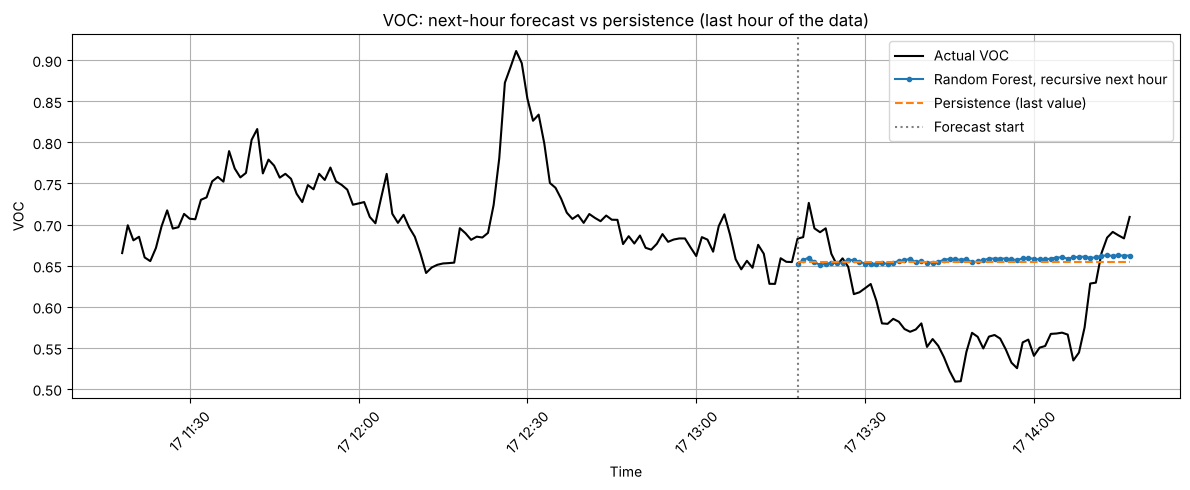

In [4]:
# --- Next-hour forecast, fed back recursively, scored on the last 60 minutes of the data ---
# The model only sees data before the forecast hour. Each prediction becomes VOC_t-1 for the next step,
# with the lag vector in the same order as in training (newest first). Humidity and temperature are not
# known in advance, so they stay at their last observed values (t-1 before the hour starts).
HORIZON = 60
origin = len(df) - HORIZON                      # position of the first forecast minute
history = list(df_scaled['VOC'].iloc[origin - SEQ_LEN:origin])   # oldest -> newest
hum_last = df_scaled['humidity'].iloc[origin - 1]
temp_last = df_scaled['temperature'].iloc[origin - 1]

rf_steps = []
for step in range(HORIZON):
    lags = history[::-1][:SEQ_LEN]              # VOC_t-1, VOC_t-2, ..., VOC_t-60
    x_step = pd.DataFrame([[hum_last, temp_last, *lags]], columns=X_train.columns)
    pred_norm = model.predict(x_step)[0]
    rf_steps.append(pred_norm)
    history.append(pred_norm)

hour_index = df.index[origin:]
actual_hour = df['VOC'].iloc[origin:].to_numpy()
rf_hour = to_voc(rf_steps)
persistence_hour = np.full(HORIZON, df['VOC'].iloc[origin - 1])
print(f"Forecast hour: {hour_index[0]} to {hour_index[-1]} (inside the test period: {hour_index[0] > train_end})")
for name, p in [("Random Forest (recursive)", rf_hour), ("Persistence (last value before the hour)", persistence_hour)]:
    print(f"{name:<42} RMSE: {root_mean_squared_error(actual_hour, p):.4f}  MAE: {mean_absolute_error(actual_hour, p):.4f}")

# --- Plot ---
plt.figure(figsize=(12, 5))
plt.plot(df['VOC'].iloc[origin - 120:], label="Actual VOC", color='black')
plt.plot(hour_index, rf_hour, label="Random Forest, recursive next hour", marker='o', markersize=3)
plt.plot(hour_index, persistence_hour, label="Persistence (last value)", linestyle='--')
plt.axvline(hour_index[0], color='grey', linestyle=':', label="Forecast start")
plt.title("VOC: next-hour forecast vs persistence (last hour of the data)")
plt.xlabel("Time")
plt.ylabel("VOC")
plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "rf_voc_next_hour.png", bbox_inches='tight')
plt.show()

In [5]:
# --- Leakage checks ---
print(f"Last train timestamp {X_train.index[-1]} < first test timestamp {X_test.index[0]}: {X_train.index[-1] < X_test.index[0]}")
print(f"Scaler fitted on rows up to {train_end} only: {scaler.n_samples_seen_ == len(df.loc[:train_end])}")
print("Features use t-1 or earlier only:", all(c.endswith(tuple(f't-{i}' for i in range(1, SEQ_LEN + 1))) for c in X.columns))

Last train timestamp 2025-06-14 16:24:00+00:00 < first test timestamp 2025-06-14 16:25:00+00:00: True
Scaler fitted on rows up to 2025-06-14 16:24:00+00:00 only: True
Features use t-1 or earlier only: True
